# Frontend Walkthrough — ESRS Reporting Assistant

This notebook provides a structured walkthrough of the **Streamlit-based frontend** (`streamlit_app/app.py`) that serves as the interactive user interface for the ESRS Regulation Bot. The application combines the empirical findings from **RQ1** (optimal retrieval configuration), **RQ2** (ESRS context injection ablation), and **RQ3** (generation quality) into a production-ready analysis tool.

**Key design principles:**
- **Research-driven defaults** — every pipeline parameter is automatically set from the best RQ1 configuration and RQ2 statistical results.
- **Multi-company support** — users can simultaneously query up to 17 sustainability reports, with parallel retrieval and an LLM-generated cross-company comparison.
- **Transparency** — the sidebar exposes the active pipeline configuration as read-only fields, making the underlying research decisions visible.

---

## 1. Setup and Project Structure

Before launching the frontend, the project requires a working Python environment with the `rag` package accessible. The application relies on:

| Component | Path | Purpose |
|:---|:---|:---|
| Application entry point | `streamlit_app/app.py` | Main Streamlit application |
| Best pipeline config | `config/best_pipeline.yaml` | Written by RQ1 — stores the winning retrieval configuration |
| RQ2 aggregate results | `rq2_aggregate_results.json` / `rq3_summary.json` | Determines whether ESRS context injection is enabled |
| Pipeline loader | `rag/pipeline/rq1_runner.py` | `load_pipeline()` and `run_query()` |
| Config utilities | `rag/config/settings.py` | `load_best_pipeline_config()`, `load_esrs_context_decision()` |
| Streamlit config | `.streamlit/config.toml` | Disables file watcher to suppress torchvision warnings |

The frontend can be launched with:

```bash
streamlit run streamlit_app/app.py --server.headless true
```

## 2. Automatic Pipeline Selection from RQ1

A central design goal of the frontend is that **no manual configuration is required**. The application reads the best-performing pipeline configuration directly from `config/best_pipeline.yaml`, which was written during the RQ1 evaluation.

RQ1 evaluated **54 pipeline configurations** (3 chunking strategies × 3 chunk sizes × 6 retrieval methods) and identified the optimal combination based on Recall@15. The winning configuration is loaded at startup and displayed in the sidebar as read-only fields.

In [1]:
# ── Demonstrate how the best pipeline config is loaded ──────────────────────

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from rag.config import load_best_pipeline_config, BEST_PIPELINE_PATH

print(f"Config path: {BEST_PIPELINE_PATH}")
print(f"Exists:      {BEST_PIPELINE_PATH.exists()}\n")

best_cfg = load_best_pipeline_config()

for key, value in best_cfg.items():
    print(f"  {key:.<30s} {value}")

Config path: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/config/best_pipeline.yaml
Exists:      True

  chunk_strategy................ fixed
  chunk_size.................... 1024
  retrieval_method.............. hybrid_rerank
  chunk_overlap_ratio........... 0.125
  top_k......................... 15
  rrf_k......................... 60
  rerank_model.................. cross-encoder/ms-marco-MiniLM-L-6-v2
  _best_pipeline_name........... fixed_1024_hybrid_rerank
  _selection_reason............. Highest recall@15 (0.9616) in RQ1.


The configuration above reveals the RQ1 winner:

| Parameter | Value | Meaning |
|:---|:---|:---|
| `chunk_strategy` | `fixed` | Fixed-size chunking (equal token windows) |
| `chunk_size` | `1024` | 1 024 tokens per chunk |
| `retrieval_method` | `hybrid_rerank` | Hybrid (dense + BM25) with cross-encoder reranking |
| `top_k` | `15` | 15 chunks retrieved per query |
| `rrf_k` | `60` | Reciprocal Rank Fusion smoothing constant |
| `rerank_model` | `cross-encoder/ms-marco-MiniLM-L-6-v2` | Lightweight cross-encoder for reranking |

In `app.py`, this is achieved by a single function call at the module level:

```python
_DISPLAY_CONFIG = load_best_pipeline_config()
```

The sidebar then renders the chunk strategy, retrieval method, and chunk size as **disabled text inputs**, ensuring the user sees the active configuration but cannot accidentally change research-optimized parameters. Only the `top_k` slider is adjustable, since it was not part of the RQ1 optimization grid.

### 📸 Screenshot: Sidebar — Pipeline Configuration

The sidebar displays the read-only pipeline configuration fields (Chunking Strategy, Retrieval Method, Chunk Size) and the adjustable *Chunks to Retrieve* slider.

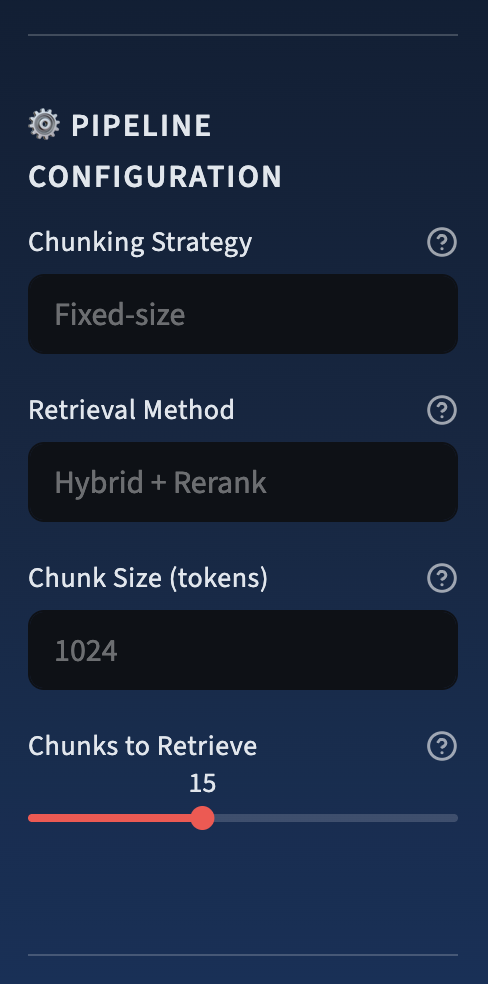

In [2]:
from IPython.display import Image, display

display(Image(filename="../streamlit_app/frontend_Images/Screenshot_1_Sidebar_PipelineConfiguration.png", width=300))

## 3. ESRS Context Injection — Decision from RQ2

RQ2 investigated whether injecting the full text of an ESRS standard into the generation prompt improves answer quality. A **Wilcoxon signed-rank test** across all 204 question–company pairs indicated no statistically significant difference.

The frontend reads this result via `load_esrs_context_decision()`, which parses the RQ2/RQ3 summary files and returns a boolean. If the test was significant, the ESRS standard text would be prepended to the generation prompt; otherwise, context injection is disabled.

In [3]:
# ── Demonstrate the ESRS context decision ──────────────────────────────────

from rag.config import load_esrs_context_decision

esrs_helps = load_esrs_context_decision()

print(f"ESRS context injection enabled: {esrs_helps}")
print()
if esrs_helps:
    print("→ RQ2 found a significant benefit. The sidebar will show an")
    print("  ESRS standard selector and inject the regulation text.")
else:
    print("→ RQ2 found no significant benefit (p = 0.8154).")
    print("  The ESRS context chip in the sidebar shows 'Disabled'.")
    print("  No ESRS standard selector is displayed.")

ESRS context injection enabled: False

→ RQ2 found no significant benefit (p = 0.8154).
  The ESRS context chip in the sidebar shows 'Disabled'.
  No ESRS standard selector is displayed.


In `app.py`, the decision controls three things:

1. **Sidebar indicator** — A styled chip (green = enabled, grey = disabled) shows the current state.
2. **ESRS standard selector** — Only rendered when `ESRS_CONTEXT_HELPS` is `True`.
3. **Prompt construction** — The `use_esrs_context` flag is passed to `run_query()`, which forwards it to the answer generator.

```python
ESRS_CONTEXT_HELPS: bool = load_esrs_context_decision()

result = run_query(
    query=query,
    companies=selected_companies,
    esrs_standard=selected_esrs,
    retriever=retriever,
    config=run_config,
    use_esrs_context=ESRS_CONTEXT_HELPS,   # ← controlled by RQ2
)
```

### 📸 Screenshot: Sidebar — ESRS Context Indicator

The grey "Disabled" chip reflects the RQ2 finding (p = 0.8154) that ESRS context injection does not significantly improve answer quality.

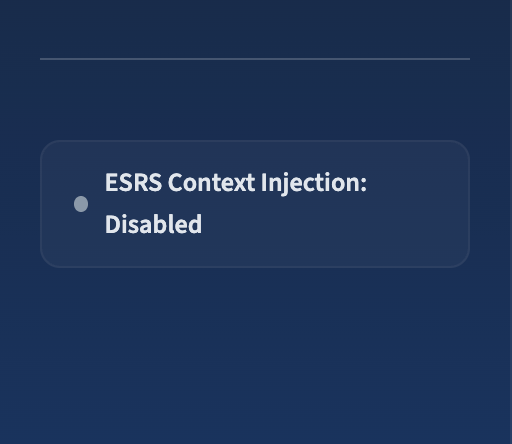

In [4]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_2_ESRS_Context_Indicator.png", width=350))

## 4. Pipeline Initialization and Caching

Loading the RAG pipeline involves building (or loading from cache) the chunk index for all 17 company reports, initializing the dense embedding model, the BM25 sparse index, and the cross-encoder reranker. This is an expensive operation (~20–40 s on first run).

The frontend uses Streamlit's `@st.cache_resource` decorator to ensure the pipeline is loaded **only once** across page reruns:

```python
@st.cache_resource(show_spinner=False)
def _load_pipeline():
    cfg = load_best_pipeline_config()
    pipeline_name = cfg.pop("_best_pipeline_name", "default")
    selection_reason = cfg.pop("_selection_reason", "")
    retriever, cfg = load_pipeline(cfg)
    return retriever, cfg, pipeline_name, selection_reason
```

Under the hood, `load_pipeline()` in `rag/pipeline/rq1_runner.py` performs the following steps:

1. **Chunk all reports** using the specified strategy and size (or load from pickle cache, keyed by `RQ1_INDEX_VERSION`).
2. **Build an `InMemoryDenseIndex`** from pre-computed NPZ embeddings (OpenAI `text-embedding-3-large`, 3072 dimensions) — this is a lightweight alternative to Qdrant that requires no external server.
3. **Build a BM25 sparse index** for the hybrid retrieval branch.
4. **Load the cross-encoder** (`ms-marco-MiniLM-L-6-v2`) for reranking.

After the pipeline loads successfully, a **status chip** appears below the hero section showing the active pipeline name (e.g., `fixed_1024_hybrid_rerank`).

### 📸 Screenshot: Pipeline Status Chip

The hero header with the green pipeline status chip showing the active configuration (`fixed_1024_hybrid_rerank`), the query input area, and the Analyze / Clear buttons.

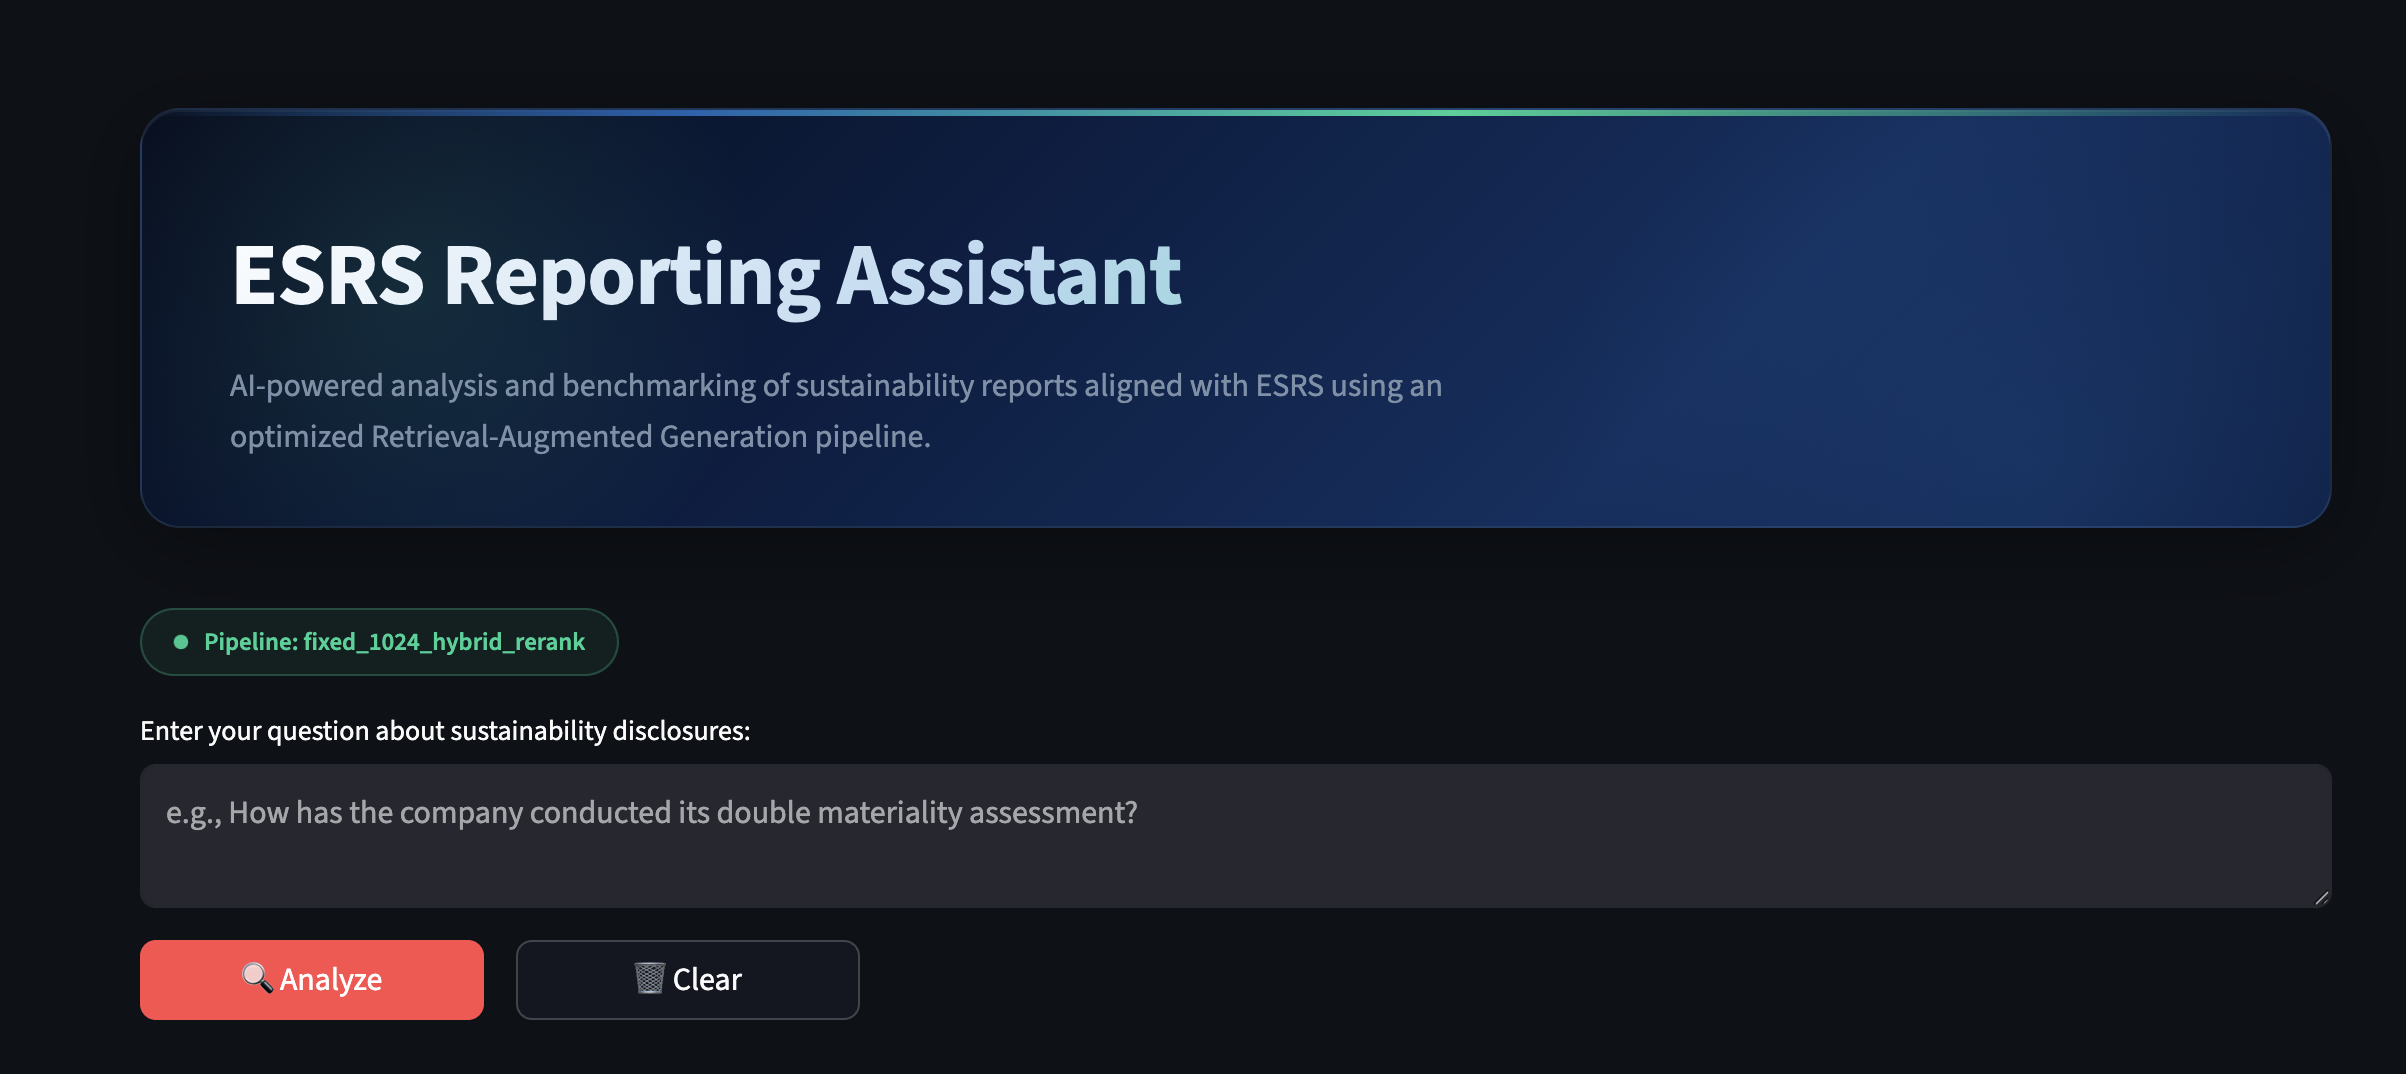

In [5]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_3_Pipeline_Status.png", width=700))

## 5. User Interface Architecture

The frontend follows a clear **sidebar → main area** layout common in data-oriented Streamlit applications.

### Sidebar Components

| Component | Type | Description |
|:---|:---|:---|
| Company selector | `st.multiselect` | Choose 1–17 companies; no default selection |
| Chunking Strategy | `st.text_input` (disabled) | Read-only, from RQ1 |
| Retrieval Method | `st.text_input` (disabled) | Read-only, from RQ1 |
| Chunk Size (tokens) | `st.text_input` (disabled) | Read-only, from RQ1 |
| Chunks to Retrieve | `st.slider` | Adjustable (5–30, default 15) |
| ESRS Context chip | Custom HTML | Green/grey indicator from RQ2 |
| ESRS Standard | `st.selectbox` | Only shown when context injection is enabled |

### Main Area Components

| Component | Description |
|:---|:---|
| Hero header | Gradient banner with title, subtitle, and accent line |
| Pipeline status chip | Shows active pipeline name after loading |
| Query input | `st.text_area` for the user's ESRS disclosure question |
| Analyze / Clear buttons | Triggers retrieval + generation |
| Results section | Single-company detail or multi-company tabs + comparison |

### 📸 Screenshot: Full Application View

Complete application layout with the sidebar (company selector, pipeline configuration, ESRS context indicator) on the left and the hero header with query area in the main panel.

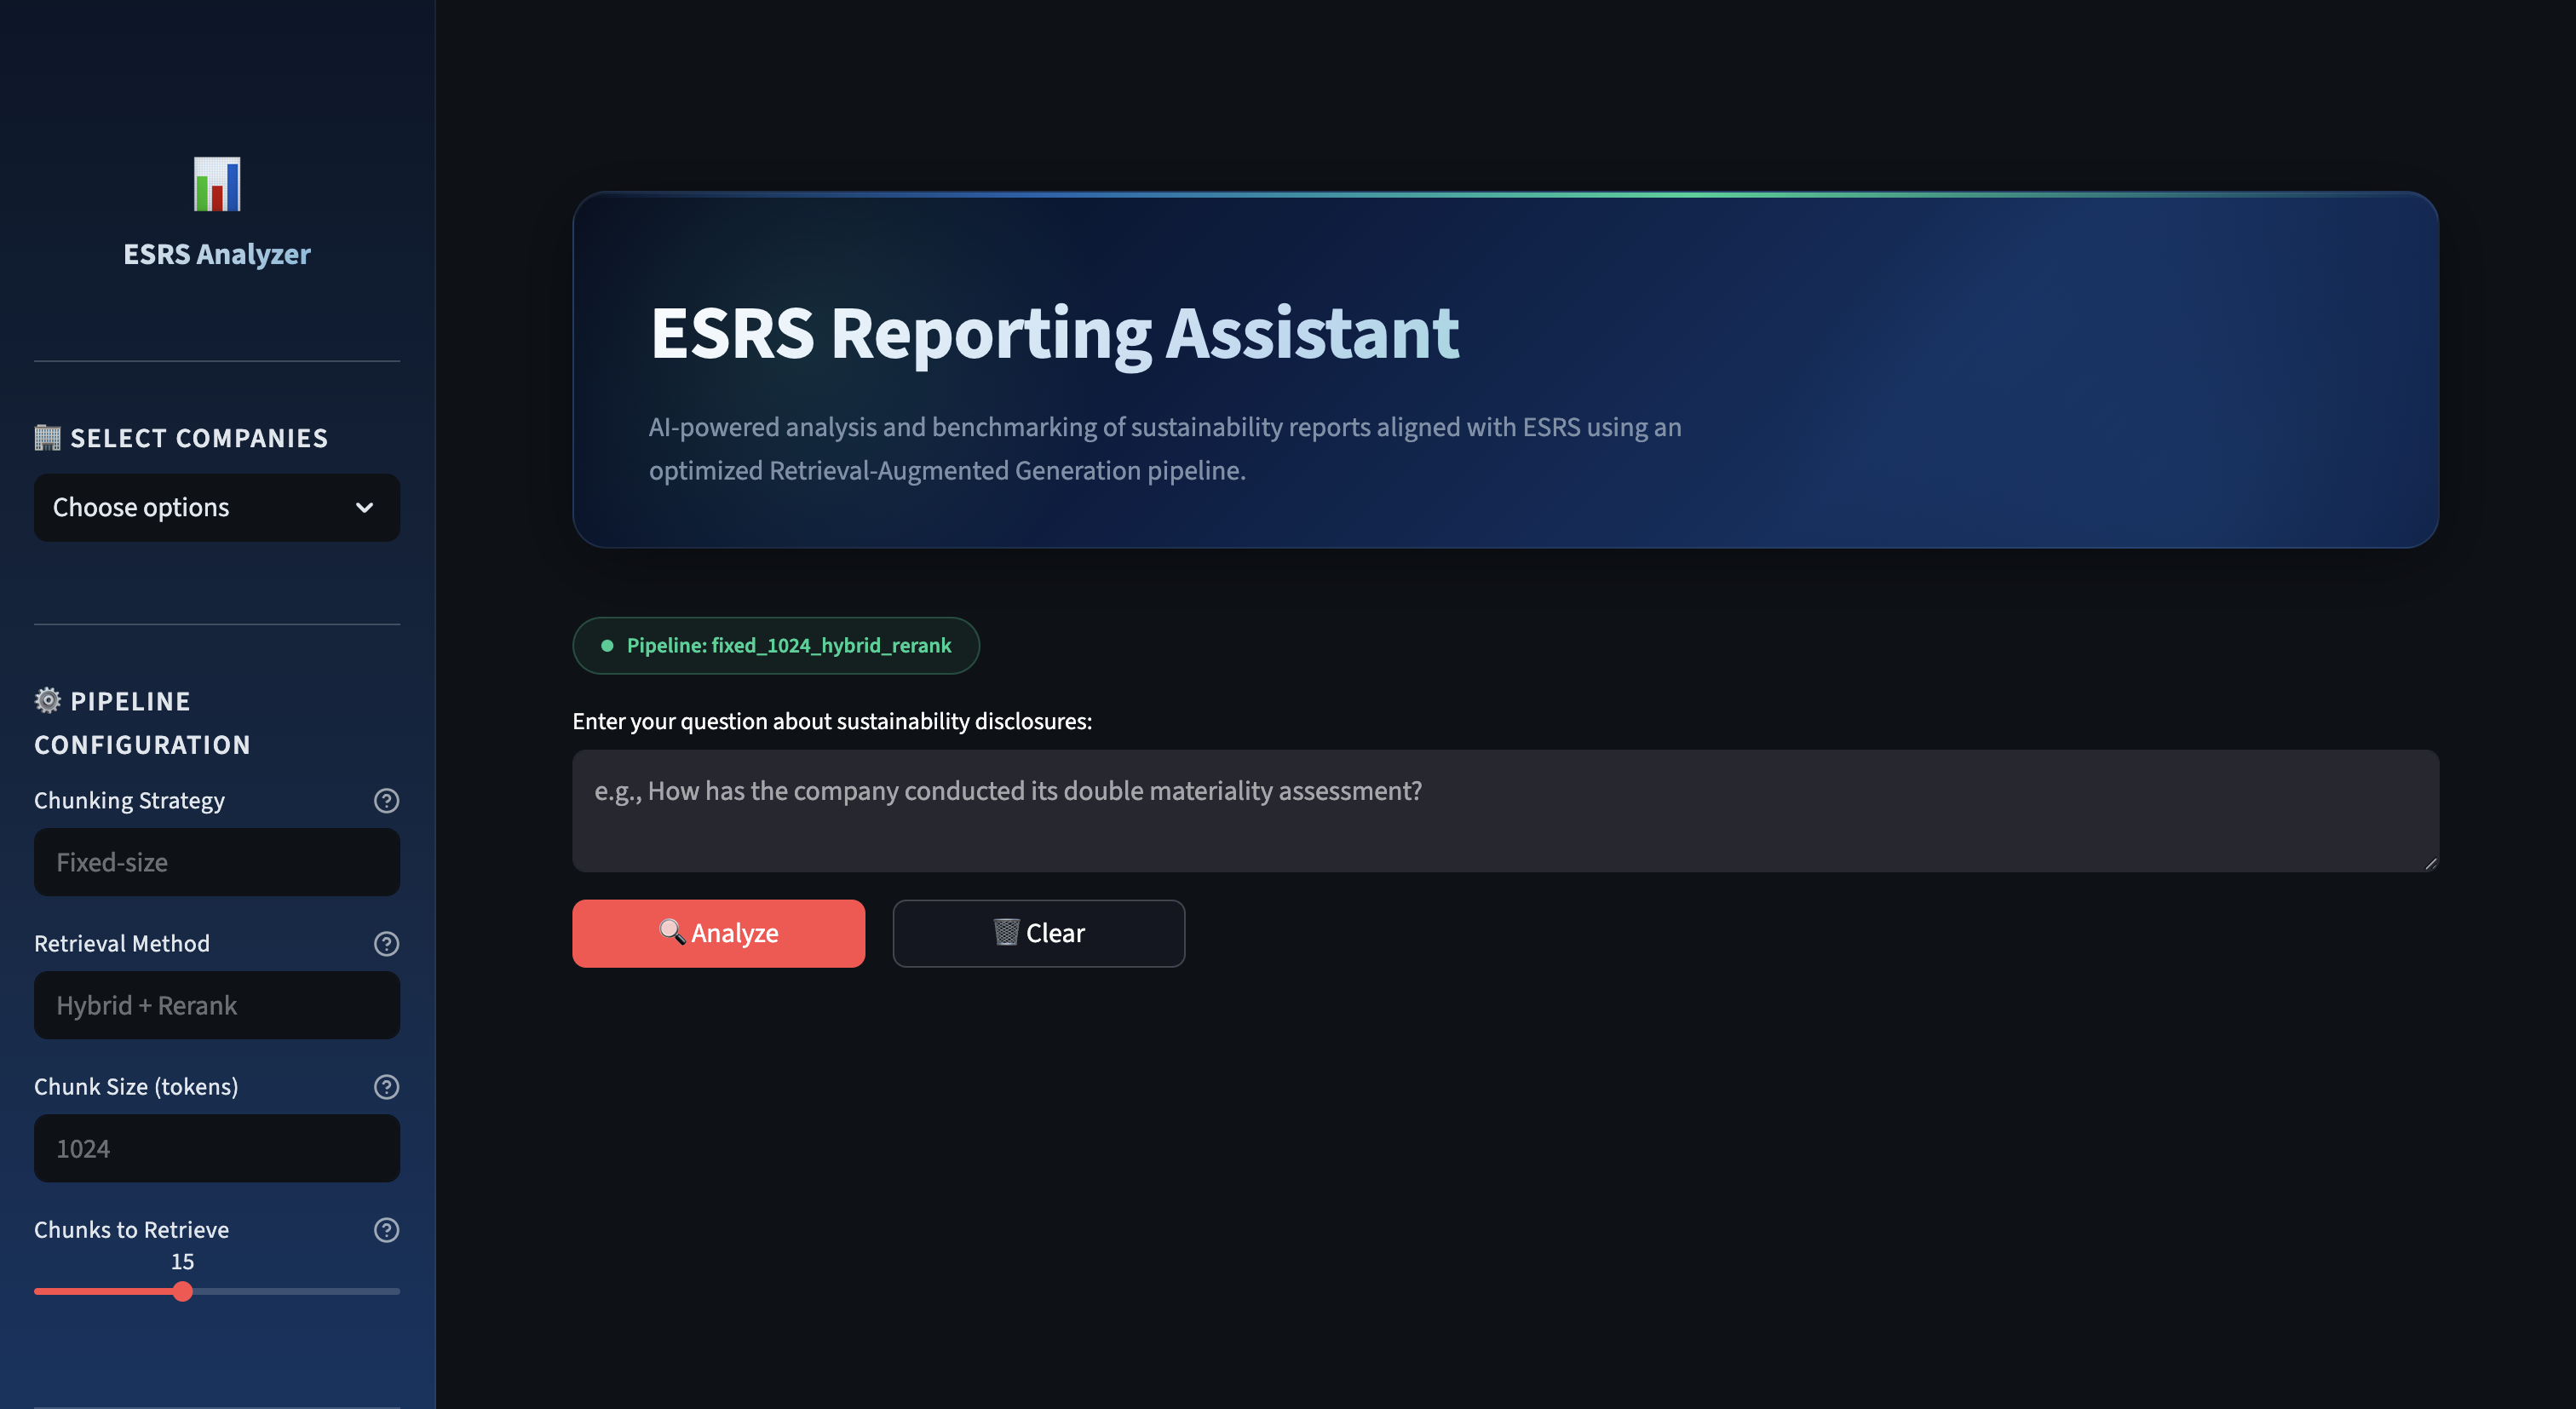

In [6]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_4_Full_Application_View.png", width=900))

## 6. Query Execution Flow

When the user clicks **"Analyze"**, the following sequence executes:

```
User Query + Selected Companies
        │
        ▼
┌─────────────────────────────────┐
│  run_query()                    │
│  ├─ ThreadPoolExecutor          │
│  │  ├─ Company A: retrieve →    │
│  │  │            rerank →       │
│  │  │            generate       │
│  │  ├─ Company B: retrieve →    │
│  │  │            rerank →       │
│  │  │            generate       │
│  │  └─ ...                      │
│  └─ Collect per-company results │
└─────────────────────────────────┘
        │
        ▼  (if multi-company)
┌─────────────────────────────────┐
│  _generate_comparison()         │
│  ├─ Structured JSON schema      │
│  ├─ Aspects: Key Strengths,     │
│  │  Key Weaknesses, Notable     │
│  │  Differences                 │
│  └─ Comparative Summary         │
└─────────────────────────────────┘
        │
        ▼
    Render Results
```

**Key implementation details:**

- **Parallel execution**: `run_query()` uses a `ThreadPoolExecutor` to process each selected company concurrently. This means querying 3 companies takes roughly the same wall-clock time as querying 1.
- **Structured generation**: The `AnswerGenerator` uses OpenAI's structured output mode (`gpt-5-mini`) with a strict JSON schema, producing fields like `direct_answer`, `key_findings`, `compliance_level`, `compliance_rationale`, `disclosure_gaps`, and `page_references`.
- **ESRS context injection**: When `use_esrs_context=True`, the full ESRS standard text is prepended to the generation prompt via `build_answer_messages()` in `rag/generation/prompts.py`.

## 7. Single-Company Result Rendering

For a single-company query, results are displayed directly in the main area through the `_render_company_result()` helper. The result view consists of three sections:

### 7.1 Analysis
The LLM-generated direct answer and key findings are displayed as a narrative text block followed by a bulleted list.

### 7.2 Sources
Each cited page from the sustainability report is shown as a styled **source card** with a page badge and section header. An expandable section reveals all retrieved passages for full traceability.

### 7.3 Compliance Assessment
A colored **compliance badge** (High = green, Medium = amber, Low = red) followed by the rationale. When the compliance level is **not** "High", disclosure gaps are listed as warning items. When the level is "High", the gaps section is intentionally hidden to avoid visual clutter.

### 📸 Screenshot: Single-Company Analysis Result

A single-company analysis for Shell, split across two screenshots: the first shows the Analysis section with key findings; the second shows the Sources (page cards with expandable passages) and the Compliance Assessment with a green "High" badge.

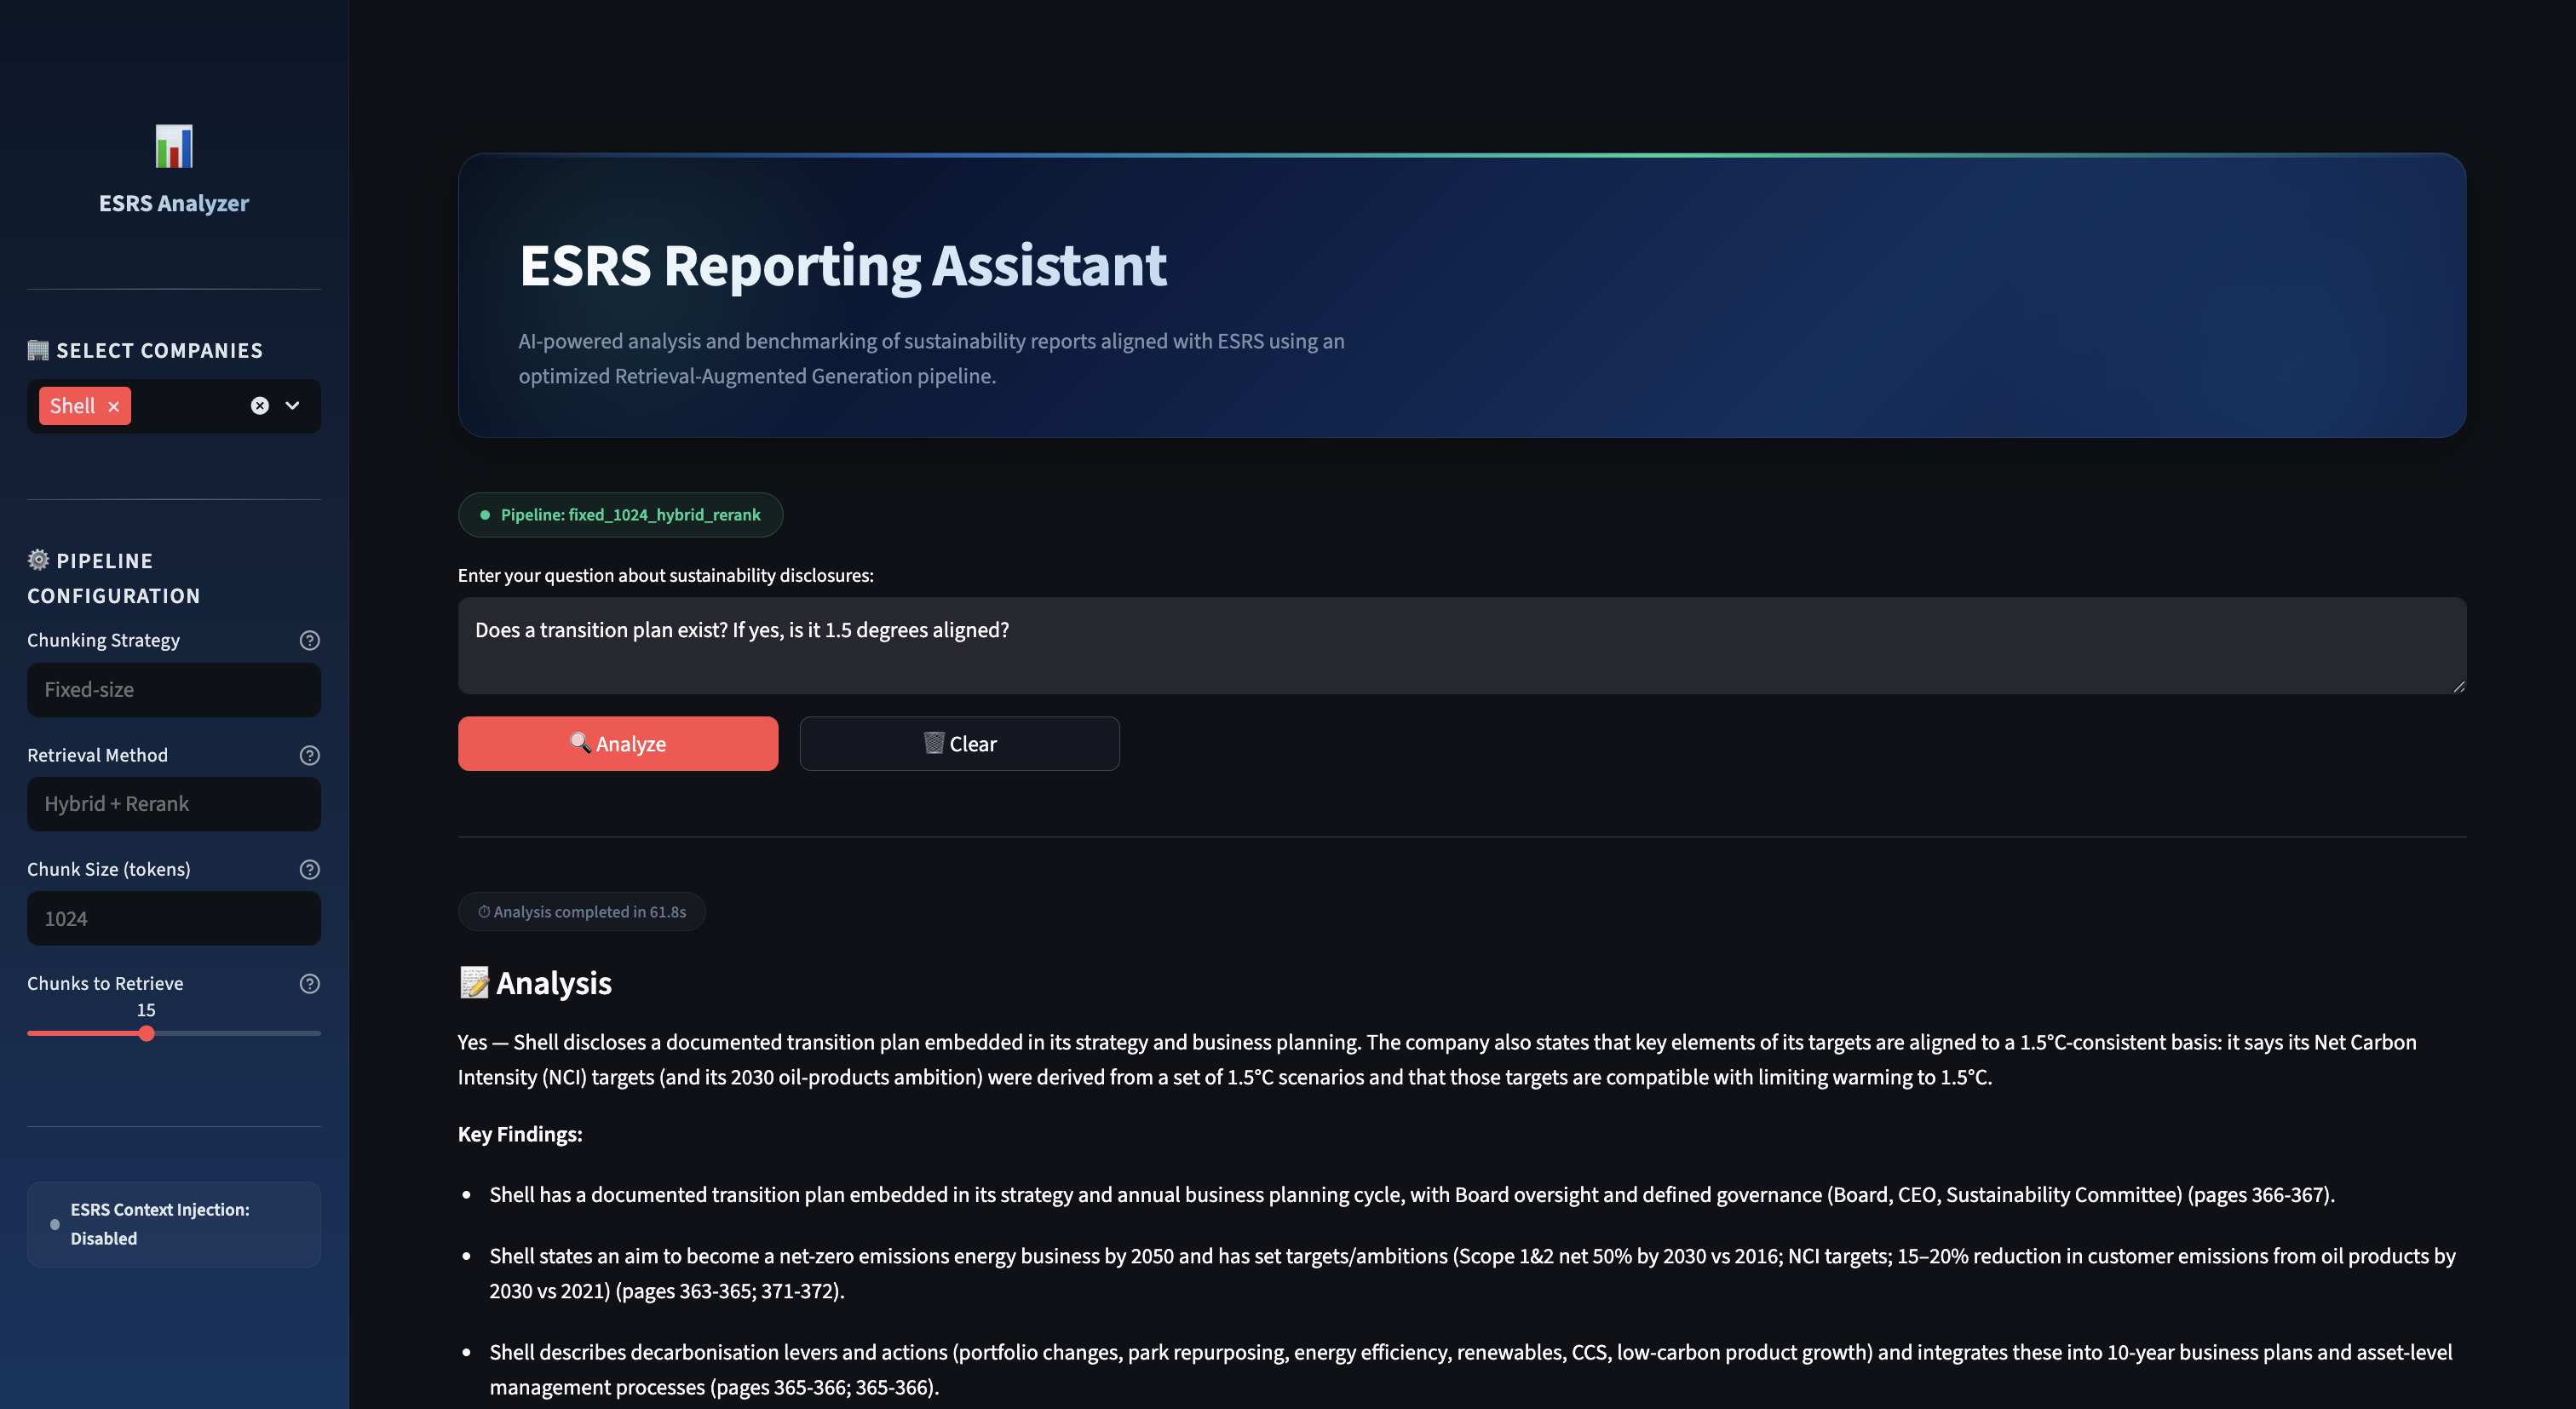

In [7]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_5_Single_Company.png", width=900))

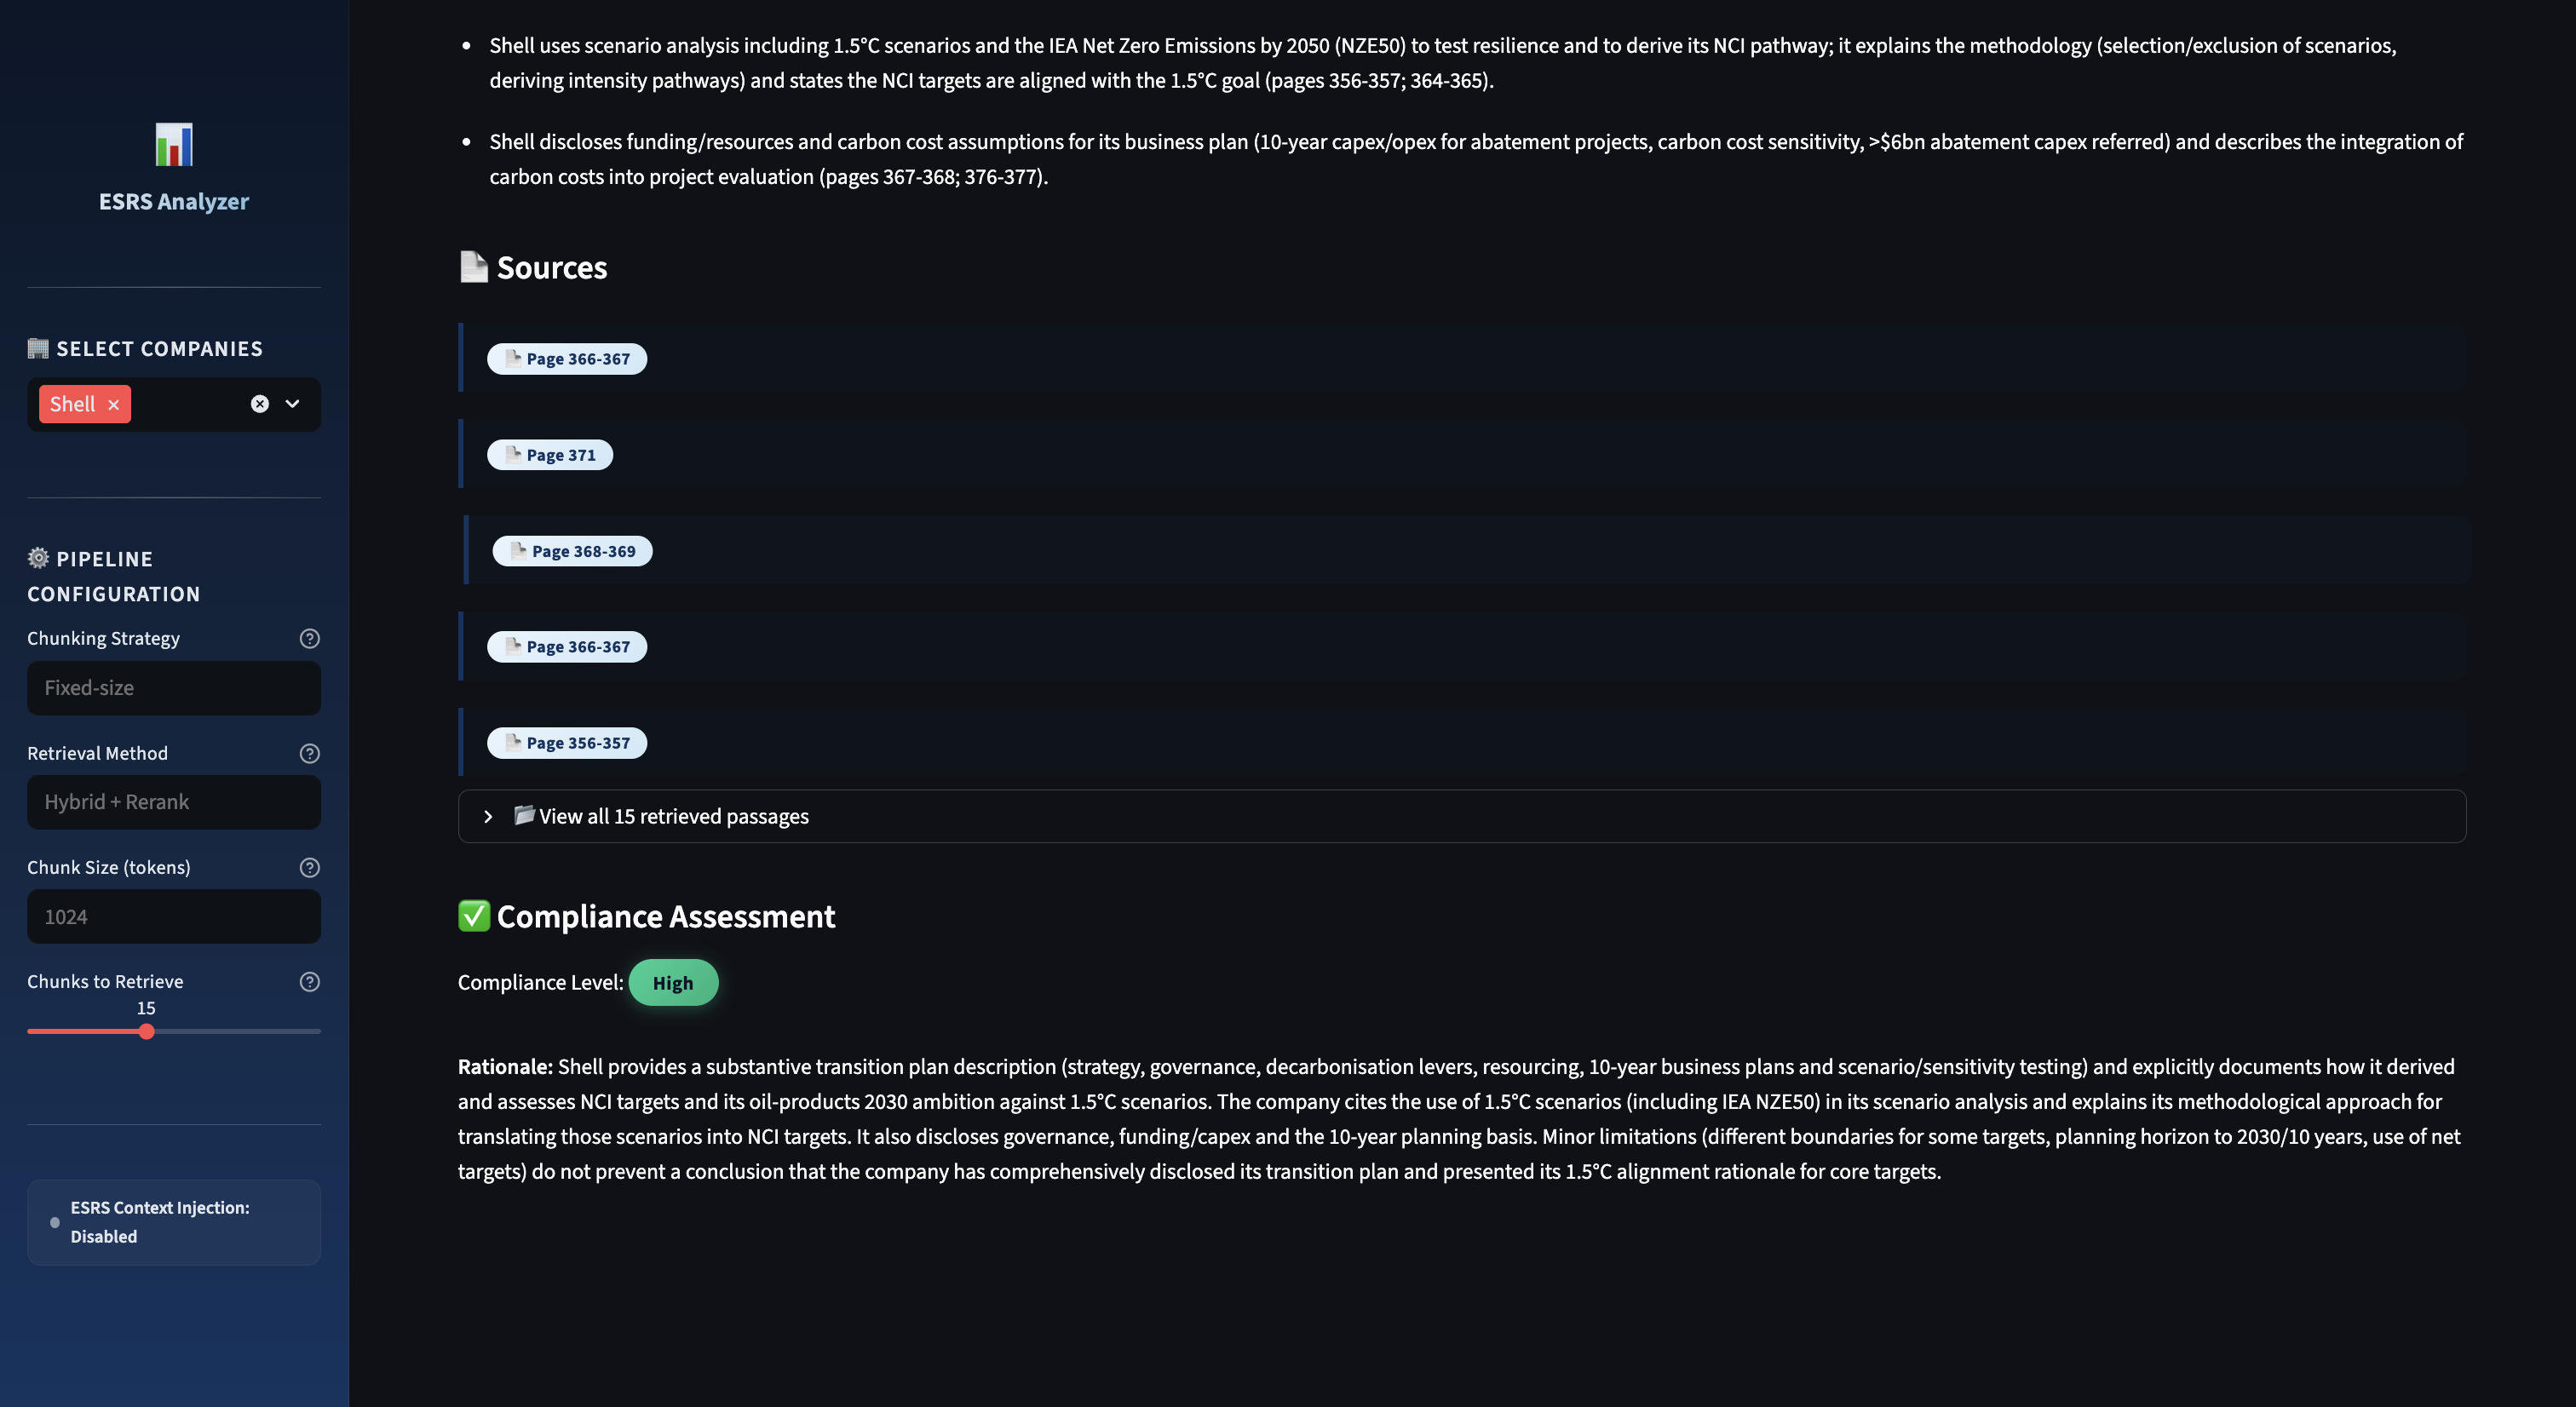

In [8]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_6_Single_Company.png", width=900))

## 8. Multi-Company Analysis and Cross-Company Comparison

When two or more companies are selected, the frontend enables its benchmarking capabilities:

1. **Compliance Overview Cards** — A row of cards at the top provides an at-a-glance comparison of compliance levels across all selected companies.

2. **Company Tabs** — Each company's detailed results (identical in structure to the single-company view) are organized into tabs, keeping the interface clean even with many companies.

3. **Cross-Company Comparison Table** — An additional LLM call (`_generate_comparison()`) produces a structured comparison using a **strict JSON schema** with the following aspects:
   - Key Strengths
   - Key Weaknesses
   - Notable Differences
   - Comparative Summary

The comparison uses OpenAI's structured output with `gpt-5-mini` and falls back to a data-driven table (`_basic_comparison()`) if the API call fails.

```python
# Triggered only when multiple companies are selected
if len(selected_companies) > 1:
    comparison = _generate_comparison(
        query=query,
        per_company=result["per_company"],
        esrs_standard=selected_esrs,
    )
    result["comparison"] = comparison
```

### 📸 Screenshot: Multi-Company — Compliance Overview Cards

Compliance overview cards for three companies (Equinor, Neste, OMV), providing an at-a-glance comparison of compliance levels (High, Medium, High).

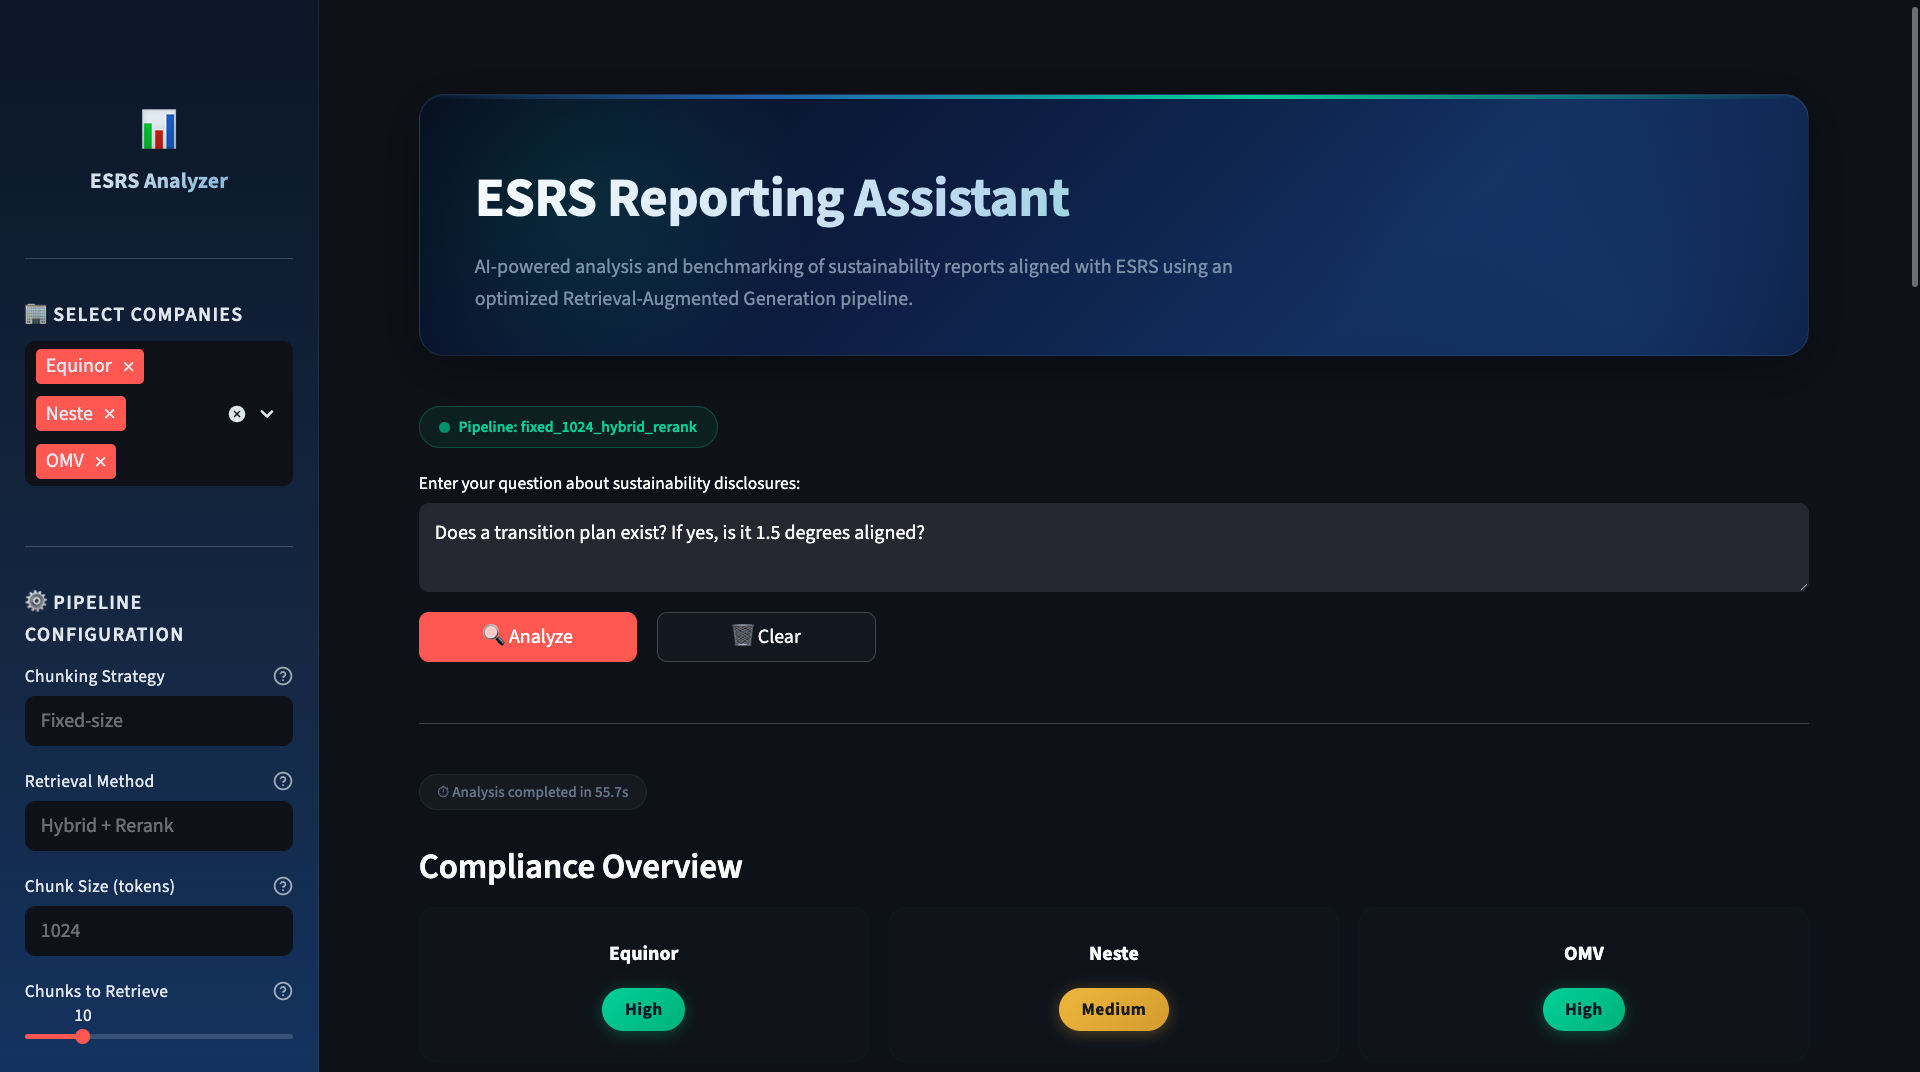

In [9]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_7_Multiple_Companies.png", width=900))

### 📸 Screenshot: Multi-Company — Company Tabs

The tabbed interface organizing each company's detailed analysis. The selected tab (OMV) shows the full Analysis section with key findings and Sources.

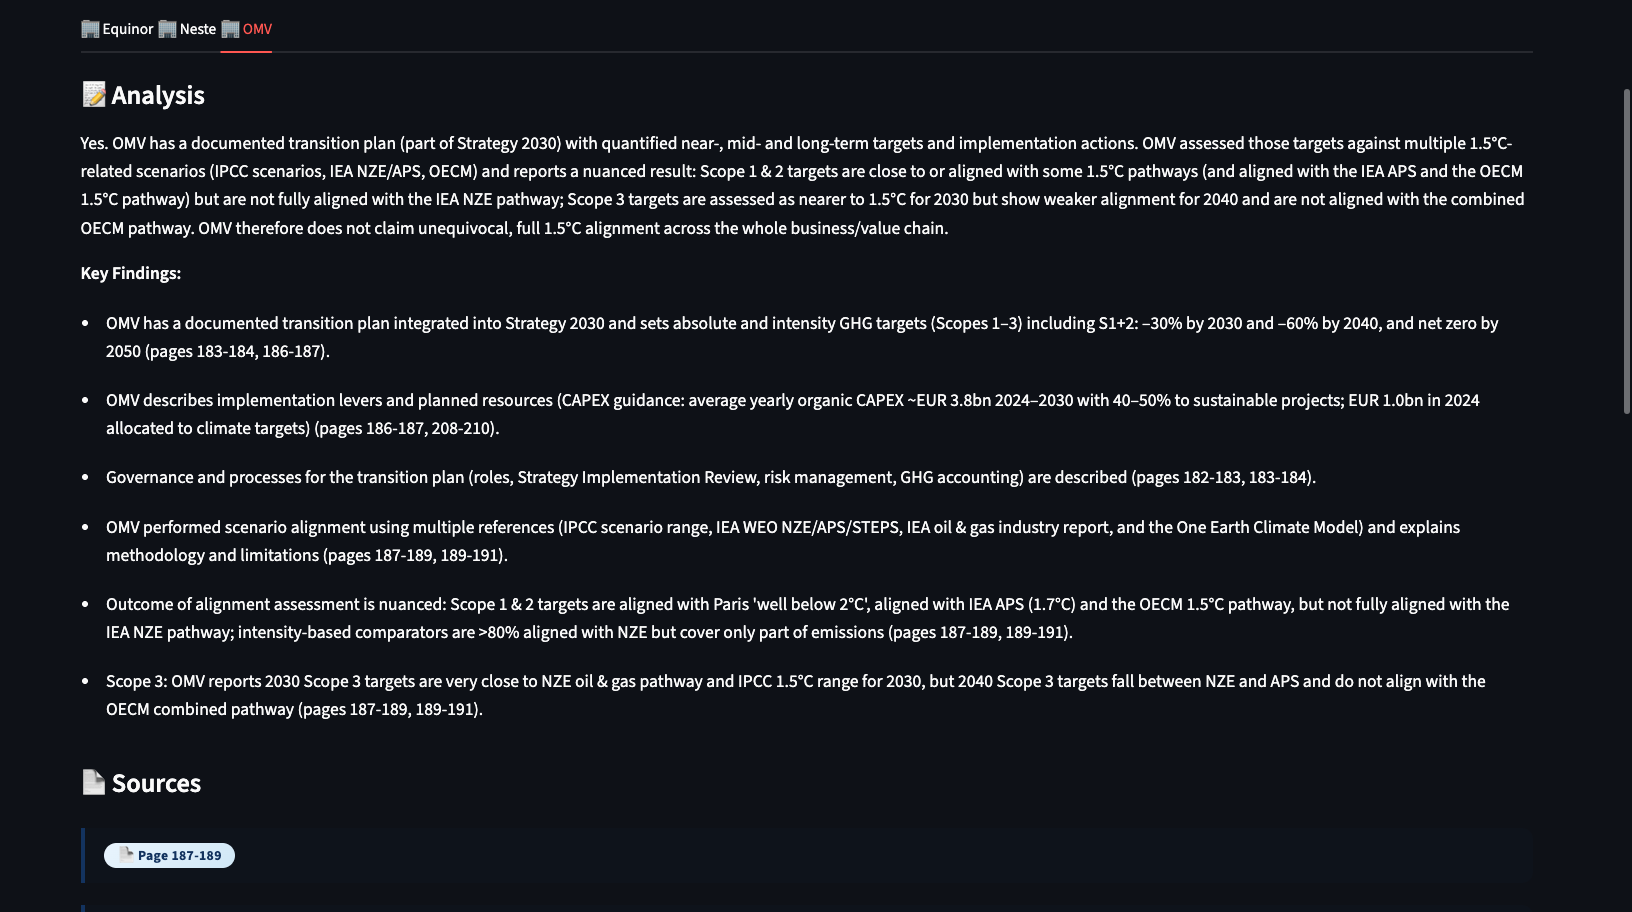

In [10]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_8_Multiple_Companies.png", width=900))

### 📸 Screenshot: Cross-Company Comparison Table

The LLM-generated comparison table with Key Strengths, Key Weaknesses, and Notable Differences rows for Equinor, Neste, and OMV, plus the Comparative Summary at the bottom.

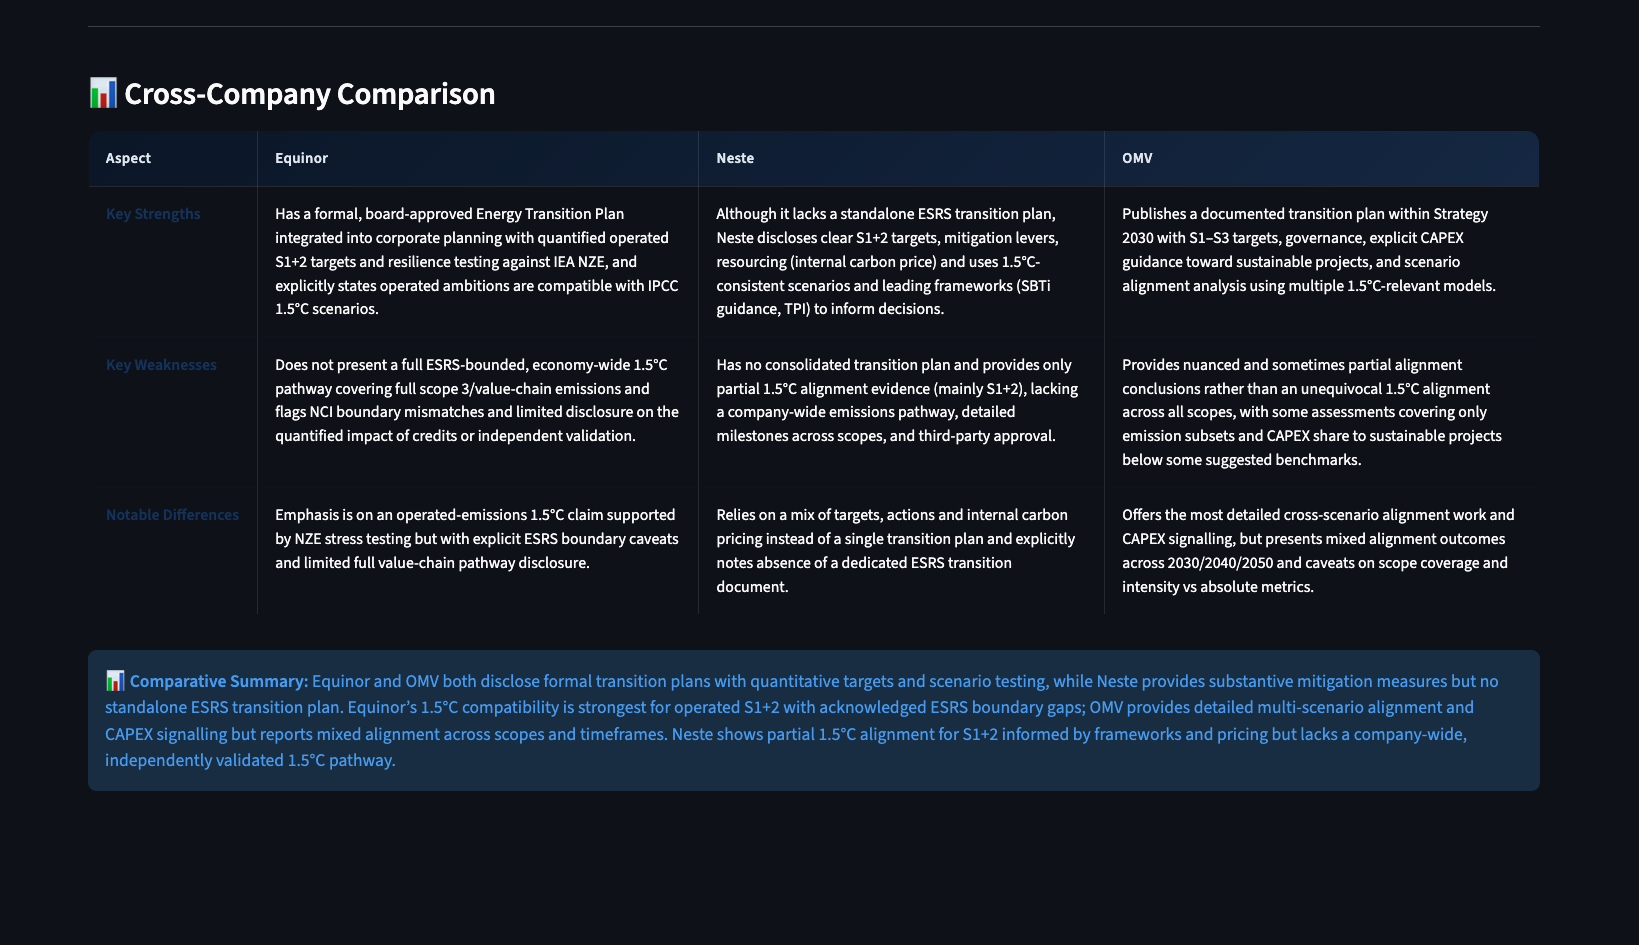

In [11]:
display(Image(filename="../streamlit_app/frontend_Images/Screenshot_9_Multiple_Companies.png", width=900))

## 9. Visual Design and Theming

The frontend employs a **premium dark-themed design** with custom CSS injected via `st.markdown(unsafe_allow_html=True)`. Key visual elements include:

| Element | Technique |
|:---|:---|
| Hero header | CSS gradient background with glassmorphism glow effects |
| Title | Gradient text via `-webkit-background-clip: text` |
| Pipeline status | Animated pulsing dot (CSS `@keyframes`) |
| Compliance badges | Color-coded gradient backgrounds (green/amber/red) |
| Source cards | Left-bordered cards with hover translate animation |
| Comparison table | Styled `<table>` with dark header row and hover states |
| Sidebar | Dark gradient background with section dividers |
| ESRS indicator | Styled chip with colored status dot |

All default Streamlit chrome (header, footer, main menu) is hidden to achieve a clean, application-like appearance. The font is set to **Inter** via Google Fonts for a modern, professional look suitable for a master thesis demonstration.

## 10. Warning Suppression and Runtime Configuration

Streamlit's file watcher scans all imported modules on every page rerun. Because the RAG pipeline imports `transformers` (which has lazy-import stubs referencing `torchvision`), the watcher generates noisy tracebacks in the terminal even when `torchvision` is not installed or needed.

The application applies a **three-layer suppression strategy**:

1. **Streamlit configuration** (`.streamlit/config.toml`):
   ```toml
   [server]
   fileWatcherType = "none"
   ```

2. **Python warnings filters** (top of `app.py`):
   ```python
   warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")
   warnings.filterwarnings("ignore", category=FutureWarning, module="transformers")
   ```

3. **Logging level override** (silences the watcher's INFO-level tracebacks):
   ```python
   logging.getLogger("streamlit.watcher.local_sources_watcher").setLevel(logging.ERROR)
   ```

Together, these ensure a **clean terminal output** during development and demonstration.

## 11. Summary

The ESRS Reporting Assistant frontend translates the empirical research from RQ1–RQ3 into a practical, user-facing tool. Its architecture ensures that:

- The **best retrieval configuration** is automatically loaded from the RQ1 evaluation results.
- The **ESRS context injection decision** is data-driven, based on the RQ2 Wilcoxon signed-rank test.
- The **generation model** produces structured, schema-validated JSON outputs that map directly to the UI components.
- **Multi-company benchmarking** is supported out of the box, with parallel retrieval and an LLM-generated comparative analysis.

The frontend serves as both a **demonstration platform** for the thesis and a **reusable prototype** for ESRS compliance analysis workflows.

---